In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.tree import DecisionTreeRegressor, export_text
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import root_mean_squared_error

%matplotlib inline

In [1]:
import pandas as pd

df = pd.read_csv("car_fuel_efficiency_2026.csv")
df.head() # shows the first 5 row

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
0,2006,Europe,Gasoline,Front-wheel drive,4,2180,6,243.0,3870,NaN,31.9
1,2008,Europe,Diesel,Front-wheel drive,4,2390,6,272.0,4210,NaN,31.3
2,1996,Asia,Gasoline,Front-wheel drive,5,2320,6,267.0,4240,17.3,27.5
3,1989,Europe,Gasoline,Front-wheel drive,4,2130,6,258.0,4490,18.7,28.5
4,1994,USA,Diesel,Front-wheel drive,3,2580,7,304.0,4510,17.5,31.0


In [2]:
df.isnull().sum()

model_year               0
origin                   0
fuel_type                0
drivetrain               0
num_doors                0
engine_displacement      0
num_cylinders            0
horsepower             877
vehicle_weight           0
acceleration           264
fuel_efficiency_mpg      0
dtype: int64

In [4]:
df.describe()

,model_year,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
count,10000.000000,10000.00000,10000.000000,10000.000000,9123.000000,10000.000000,9736.000000,10000.000000
mean,1999.549500,3.50400,2268.807000,6.035200,254.446016,4286.754000,18.888044,29.997700
std,14.207925,0.95209,183.447355,0.542578,22.844613,266.212491,1.279543,2.930245
min,1975.000000,2.00000,1590.000000,4.000000,171.000000,3320.000000,14.000000,19.800000
25%,1987.000000,3.00000,2150.000000,6.000000,239.000000,4110.000000,18.000000,28.000000
50%,2000.000000,4.00000,2270.000000,6.000000,254.000000,4280.000000,18.900000,30.000000
75%,2012.000000,4.00000,2390.000000,6.000000,270.000000,4470.000000,19.700000,31.900000
max,2024.000000,5.00000,3110.000000,8.000000,334.000000,5460.000000,23.800000,41.200000


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   model_year           10000 non-null  int64  
 1   origin               10000 non-null  str    
 2   fuel_type            10000 non-null  str    
 3   drivetrain           10000 non-null  str    
 4   num_doors            10000 non-null  int64  
 5   engine_displacement  10000 non-null  int64  
 6   num_cylinders        10000 non-null  int64  
 7   horsepower           9123 non-null   float64
 8   vehicle_weight       10000 non-null  int64  
 9   acceleration         9736 non-null   float64
 10  fuel_efficiency_mpg  10000 non-null  float64
dtypes: float64(3), int64(5), str(3)
memory usage: 859.5 KB


In [6]:
df.describe(include="object")

/var/folders/3n/ltmv65_n0lq0g_dyltmjkpbw0000gn/T/ipykernel_31494/702825166.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include="object")


,origin,fuel_type,drivetrain
count,10000,10000,10000
unique,3,3,3
top,USA,Gasoline,Front-wheel drive
freq,4202,6913,5519


In [7]:
df.duplicated().sum()

np.int64(0)

In [ ]:
# df['acc_missing'] = df['acceleration'].isna()
# df.groupby('fuel_type')['acc_missing'].mean()
# df.groupby('acc_missing')['fuel_efficiency_mpg'].mean()


In [8]:
df["acceleration"] = df["acceleration"].fillna(0)
df["horsepower"] = df["horsepower"].fillna(0)

In [9]:
missing = df.isnull().mean().sort_values(ascending=False) * 100
print(missing[missing > 0])

Series([], dtype: float64)


In [12]:
def split_data(df, target="fuel_efficiency_mpg", test_size=0.2, random_state=1):
    # first cut off the test set, then split the rest into train and validation
    df_full_train, df_test = train_test_split(df, test_size=test_size, random_state=random_state)
    val_ratio = test_size / (1 - test_size)  # val same size as test: 0.2 / 0.8 = 0.25 of the remaining data
    df_train, df_val = train_test_split(df_full_train, test_size=val_ratio, random_state=random_state)

    df_train = df_train.reset_index(drop=True)
    df_val = df_val.reset_index(drop=True)
    df_test = df_test.reset_index(drop=True)

    # separate the target so the model can't see the answer
    y_train = df_train.pop(target).values
    y_val = df_val.pop(target).values
    y_test = df_test.pop(target).values

    return df_train, df_val, df_test, y_train, y_val, y_test

In [ ]:
df_train, df_val, df_test, y_train, y_val, y_test = split_data(df)

dv = DictVectorizer(sparse=True)

# fit on train only, then reuse the same columns for val and test
X_train = dv.fit_transform(df_train.to_dict(orient="records"))
X_val = dv.transform(df_val.to_dict(orient="records"))
X_test = dv.transform(df_test.to_dict(orient="records"))

X_train.shape, X_val.shape, X_test.shape

## Question 1

Train a decision tree regressor with `max_depth=1`. Which original feature is used for splitting the data?

In [ ]:
dt = DecisionTreeRegressor(max_depth=1)
dt.fit(X_train, y_train)

print(export_text(dt, feature_names=list(dv.get_feature_names_out())))

# map a one-hot name like 'origin=USA' back to its original column
split_feature = dv.get_feature_names_out()[dt.tree_.feature[0]]
original_column = split_feature.split("=")[0]
print("Split feature:", original_column)

## Question 2

Train a random forest regressor with `n_estimators=10`, `random_state=1`, `n_jobs=-1`. What's the RMSE of this model on the validation data?

In [ ]:
rf = RandomForestRegressor(n_estimators=10, random_state=1, n_jobs=-1)
rf.fit(X_train, y_train)

y_pred = rf.predict(X_val)
rmse = root_mean_squared_error(y_val, y_pred)
print("Validation RMSE:", round(rmse, 3))

## Question 3

Try `n_estimators` in `[10, 50, 100, 150]` with `random_state=1`, and evaluate each model on the validation dataset.

In [ ]:
scores = []

for n in [10, 50, 100, 150]:
    rf = RandomForestRegressor(n_estimators=n, random_state=1, n_jobs=-1)
    rf.fit(X_train, y_train)

    y_pred = rf.predict(X_val)
    rmse = root_mean_squared_error(y_val, y_pred)
    scores.append((n, round(rmse, 3)))

df_scores = pd.DataFrame(scores, columns=["n_estimators", "rmse"])
df_scores

In [ ]:
plt.plot(df_scores.n_estimators, df_scores.rmse, marker="o")
plt.xlabel("n_estimators")
plt.ylabel("Validation RMSE")
plt.show()

## Question 4

For each `max_depth` in `[10, 15, 20, 25]`, try `n_estimators` in `[10, 50, 100, 150]` with `random_state=1` and calculate the mean RMSE. What's the best `max_depth`?

In [47]:
scores = []

for d in [10, 15, 20, 25]:
    for n in [10, 50, 100, 150]:
        rf = RandomForestRegressor(n_estimators=n, max_depth=d, random_state=1, n_jobs=-1)
        rf.fit(X_train, y_train)

        y_pred = rf.predict(X_val)
        rmse = root_mean_squared_error(y_val, y_pred)
        scores.append((d, n, rmse))

df_scores = pd.DataFrame(scores, columns=["max_depth", "n_estimators", "rmse"])

# average over n_estimators for each depth; lowest mean RMSE wins
df_scores.groupby("max_depth")["rmse"].mean().round(3)

max_depth
10    1.754
15    1.784
20    1.788
25    1.787
Name: rmse, dtype: float64

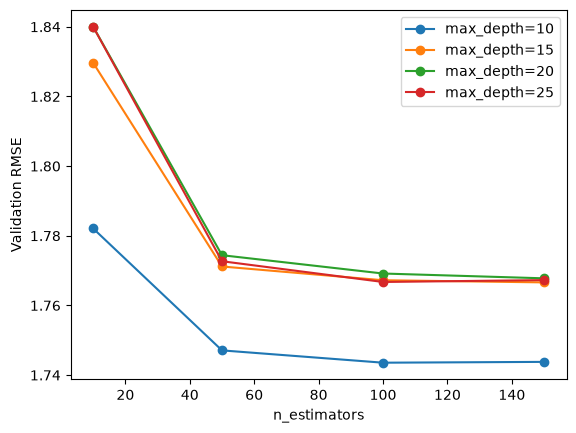

In [48]:
for d in [10, 15, 20, 25]:
    df_subset = df_scores[df_scores.max_depth == d]
    plt.plot(df_subset.n_estimators, df_subset.rmse, marker="o", label=f"max_depth={d}")

plt.xlabel("n_estimators")
plt.ylabel("Validation RMSE")
plt.legend()
plt.show()

### Question 5

In [50]:
rf = RandomForestRegressor(n_estimators=10, max_depth=20, random_state=1, n_jobs=-1)
rf.fit(X_train, y_train)

# importances come in the same order as the DictVectorizer columns
df_importances = pd.DataFrame({
    "feature": dv.get_feature_names_out(),
    "importance": rf.feature_importances_
}).sort_values("importance", ascending=False)

df_importances


,feature,importance
9,model_year,0.295915
15,vehicle_weight,0.203067
6,fuel_type=Gasoline,0.160712
8,horsepower,0.078468
4,engine_displacement,0.061152
0,acceleration,0.055342
14,origin=USA,0.042268
2,drivetrain=Front-wheel drive,0.020108
11,num_doors,0.019364
5,fuel_type=Diesel,0.018045


### Question 6
# Train Gradient Boosting Model - XGBoost

In [51]:
import xgboost as xgb

In [54]:
features = list(dv.get_feature_names_out())

dtrain = xgb.DMatrix(X_train, label=y_train, feature_names=features)
dval = xgb.DMatrix(X_val, label=y_val, feature_names=features)

# evaluated after every boosting round
watchlist = [(dtrain, "train"), (dval, "val")]
watchlist

[(<xgboost.core.DMatrix at 0x14125fb90>, 'train'),
 (<xgboost.core.DMatrix at 0x1424ac5f0>, 'val')]

In [62]:
xgb_params = {
    'eta': 1.0, 
    'max_depth': 6,
    'min_child_weight': 1,
    
    'objective': 'reg:squarederror',
    'nthread': 8,
    
    'seed': 1,
    'verbosity': 1,
}


### Compare eta 0.3 vs 1.0

In [63]:
def parse_evals(evals_result):
    # turn XGBoost's per-round scores into a dataframe
    return pd.DataFrame({
        "num_iter": range(len(evals_result["train"]["rmse"])),
        "train_rmse": evals_result["train"]["rmse"],
        "val_rmse": evals_result["val"]["rmse"],
    })


scores = {}

for eta in [0.3, 1.0]:
    params = {**xgb_params, "eta": eta}
    evals_result = {}

    xgb.train(
        params,
        dtrain,
        num_boost_round=100,
        evals=watchlist,
        evals_result=evals_result,
        verbose_eval=False,
    )
    scores[eta] = parse_evals(evals_result)

# best validation RMSE for each eta, and the round where it happened
df_best = pd.DataFrame([
    {
        "eta": eta,
        "best_iter": df_eta.val_rmse.idxmin(),
        "best_val_rmse": round(df_eta.val_rmse.min(), 3),
        "final_val_rmse": round(df_eta.val_rmse.iloc[-1], 3),
    }
    for eta, df_eta in scores.items()
])

df_best

,eta,best_iter,best_val_rmse,final_val_rmse
0,0.3,10,1.732,1.826
1,1.0,2,1.849,2.247


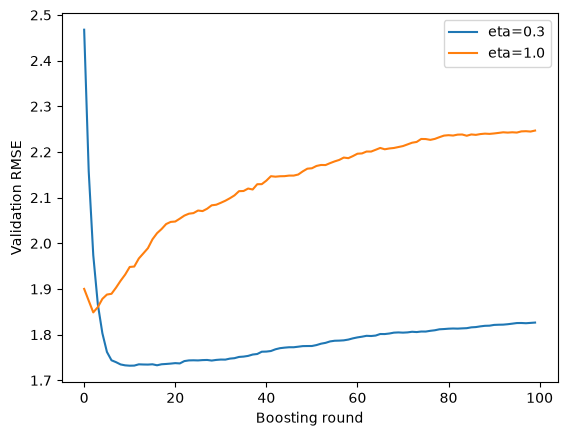

In [61]:
for eta, df_eta in scores.items():
    plt.plot(df_eta.num_iter, df_eta.val_rmse, label=f"eta={eta}")

plt.xlabel("Boosting round")
plt.ylabel("Validation RMSE")
plt.legend()
plt.show()